# Gold forecasting with LSTM

A compact LSTM uses the same data, output targets, folds and initial search budget as GRU.
Only the recurrent cell differs. Each fold starts with fresh weights and fresh fitted preprocessing.
The small initial architecture is deliberate because this dataset contains only a few thousand daily prices.

Run notebook 01 first. Review the shared audit and release assumptions before interpreting errors.

In [1]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from gold_common_utils import ROOT, load_config
# Load the shared experiment configuration.
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /home/kosala/git-repos/exps/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Load the shared panel and evaluation contract

In [2]:
from gold_common_utils import load_prepared, feature_columns, forecast_origins, metrics
from gold_model_utils import (DEFAULT_TRIALS, run_cross_validation, evaluate_holdout,
                              refit_and_forecast, fit_model, predict_model)
KIND = 'lstm'
# Reuse the processed data and folds created by notebook 01.
panel, features, folds = load_prepared()
display(folds)
print('Observed target:', panel.y.notna().sum())

,fold,cutoff,stop
0,cv_1,2175,2301
1,cv_2,2301,2427
2,cv_3,2427,2553
3,cv_4,2553,2679
4,cv_5,2679,2805
5,holdout,2805,3057


Observed target: 2646


## 2. Inspect input feature groups and candidate settings
`gold_only` establishes whether external factors improve an already useful gold-history model.
The initial search is intentionally small; expand it using development results only.
All candidate selection uses earlier inner validation. Read the adapters in `gold_model_utils.py`
for the explicit training and prediction logic.

In [3]:
# Show the exact candidates and the feature columns used per group.
trials = [dict(trial) for trial in DEFAULT_TRIALS[KIND]]
display(pd.DataFrame(trials))
for group in ['gold_only', 'external']:
    print(group, feature_columns(features, group, KIND))
# Change this local list to add candidates; keep comparable GRU/LSTM budgets.

,group,lookback,units
0,gold_only,20,32
1,external,20,32
2,external,60,32


gold_only ['gold_latest', 'gold_missing', 'gold_ret_5', 'gold_ret_20', 'gold_vol_20', 'year_sin', 'year_cos', 'weekday']
external ['gold_latest', 'gold_missing', 'gold_ret_5', 'gold_ret_20', 'gold_vol_20', 'year_sin', 'year_cos', 'weekday', 'dxy', 'fed', 'yield10', 'cpi_yoy', 'cpi_mom', 'gpr_ma7', 'gpr_acts_ma7', 'gpr_threats_ma7', 'brent_spot', 'wti', 'yield_spread', 'dxy_age_days', 'gpr_ma7_age_days', 'wti_missing']


## 3. Inspect sequence shapes and architecture

In [4]:
from gold_model_utils import sequence_rows, build_network
# Inspect the training window and network output shape before fitting.
example = trials[0]
cutoff = int(folds.iloc[0].cutoff)
rows = sequence_rows(panel, cutoff, example['lookback'], cfg['horizons'])
columns = feature_columns(features, example['group'], KIND)
print('Eligible windows:', len(rows))
print('Input shape: (batch, lookback, features) =', (None, example['lookback'], len(columns)))
print('Output shape:', (None, len(cfg['horizons'])))
network = build_network(KIND, example['lookback'], len(columns), len(cfg['horizons']), example['units'])
network.summary()

Eligible windows: 1270
Input shape: (batch, lookback, features) = (None, 20, 8)
Output shape: (None, 3)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,827 (22.76 KB)

 Trainable params: 5,827 (22.76 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Run nested walk-forward development evaluation
This cell performs actual training and may take time. Each fold reports inner candidate scores,
selects a configuration, refits it, and predicts the outer block. Forecasting uses only information
available at each origin. Outer labels are used only for scoring.

For a quick installation check, use one fold and one candidate. Restore the full settings before
comparing models or making performance claims.

In [5]:
# Full defaults: five outer folds and all candidates above.
cv_folds = folds
# Full training; results are checkpointed to artifacts/<kind>/ after each fold.
cv_predictions, cv_metrics, selections = run_cross_validation(
    KIND, panel, features, cv_folds, cfg, trials=trials)
display(cv_metrics)
display(selections)

lstm: cv_1; train through 2023-06-08


E0000 00:00:1793546906.513095  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793546916.041334  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

  candidate 1/3: inner MAE=43.949


E0000 00:00:1793546921.448020  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793546928.527177  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

  candidate 2/3: inner MAE=45.688


E0000 00:00:1793546934.948028  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793546947.022238  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

... (32 outputs left out)

  candidate 3/3: inner MAE=73.123


E0000 00:00:1793547138.184889  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793547144.229145  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,lstm,cv_1,1,5,11.491975,12.807640,0.585539,1.194062,9.580000,-0.199580
1,lstm,cv_1,5,5,20.107087,25.967155,1.036967,2.089207,19.620000,-0.024826
2,lstm,cv_1,20,4,26.248442,31.854938,1.361131,2.727318,22.650000,-0.158872
3,lstm,cv_2,1,5,11.668717,19.143491,0.571431,1.217606,11.254000,-0.036851
4,lstm,cv_2,5,4,45.987978,56.909458,2.160772,4.798750,46.242500,0.005504
5,lstm,cv_2,20,6,81.732023,105.787515,3.613252,8.528567,76.023333,-0.075091
6,lstm,cv_3,1,4,16.085279,17.392766,0.639852,1.648476,13.507500,-0.190841
7,lstm,cv_3,5,4,33.223406,45.083431,1.284760,3.404852,26.272500,-0.264570
8,lstm,cv_3,20,4,63.280424,78.766962,2.567104,6.485201,55.287500,-0.144570
9,lstm,cv_4,1,4,25.648096,27.444466,0.925953,2.551100,26.072500,0.016278


,candidate,inner_MAE,params,fold
0,0,43.948796,"{""group"": ""gold_only"", ""lookback"": 20, ""units""...",cv_1
1,1,45.687931,"{""group"": ""external"", ""lookback"": 20, ""units"":...",cv_1
2,2,44.637953,"{""group"": ""external"", ""lookback"": 60, ""units"":...",cv_1
3,0,19.282501,"{""group"": ""gold_only"", ""lookback"": 20, ""units""...",cv_2
4,1,31.349339,"{""group"": ""external"", ""lookback"": 20, ""units"":...",cv_2
5,2,37.465517,"{""group"": ""external"", ""lookback"": 60, ""units"":...",cv_2
6,0,46.462906,"{""group"": ""gold_only"", ""lookback"": 20, ""units""...",cv_3
7,1,48.379119,"{""group"": ""external"", ""lookback"": 20, ""units"":...",cv_3
8,2,45.986446,"{""group"": ""external"", ""lookback"": 60, ""units"":...",cv_3
9,0,31.053824,"{""group"": ""gold_only"", ""lookback"": 20, ""units""...",cv_4


## 5. Review errors by horizon, baseline skill, and prediction bias

,MAE,RMSE,MAPE,MASE,skill_vs_persistence
horizon,,,,,
1,20.125558,23.956447,0.762941,1.999304,-0.078700
5,52.433925,64.962632,1.886013,5.233026,-0.016279
20,87.814707,117.677996,3.030587,8.736989,-0.030778


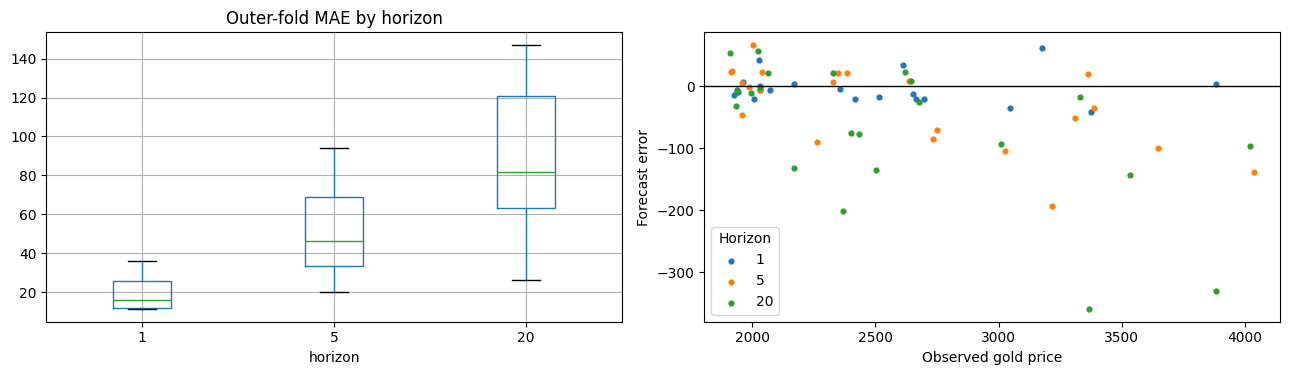

In [6]:
# Summarize outer error by horizon and check prediction bias per model.
display(cv_metrics.groupby('horizon')[['MAE', 'RMSE', 'MAPE', 'MASE', 'skill_vs_persistence']].mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cv_metrics.boxplot(column='MAE', by='horizon', ax=axes[0])
axes[0].set_title('Outer-fold MAE by horizon')
for horizon, group in cv_predictions.groupby('horizon'):
    observed = group.dropna(subset=['actual'])
    axes[1].scatter(observed.actual, observed.prediction - observed.actual, s=12, label=str(horizon))
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xlabel('Observed gold price')
axes[1].set_ylabel('Forecast error')
axes[1].legend(title='Horizon')
plt.suptitle('')
plt.tight_layout()

## 6. Plot development forecasts against observed prices

These figures use the fixed-origin predictions from each outer fold:
1. full observed history with every outer prediction;
2. actual vs forecast for each horizon;
3. training context plus test block per fold;
4. actual vs predicted price per horizon.
Each plot is also saved to `artifacts/<model>/plots/`.

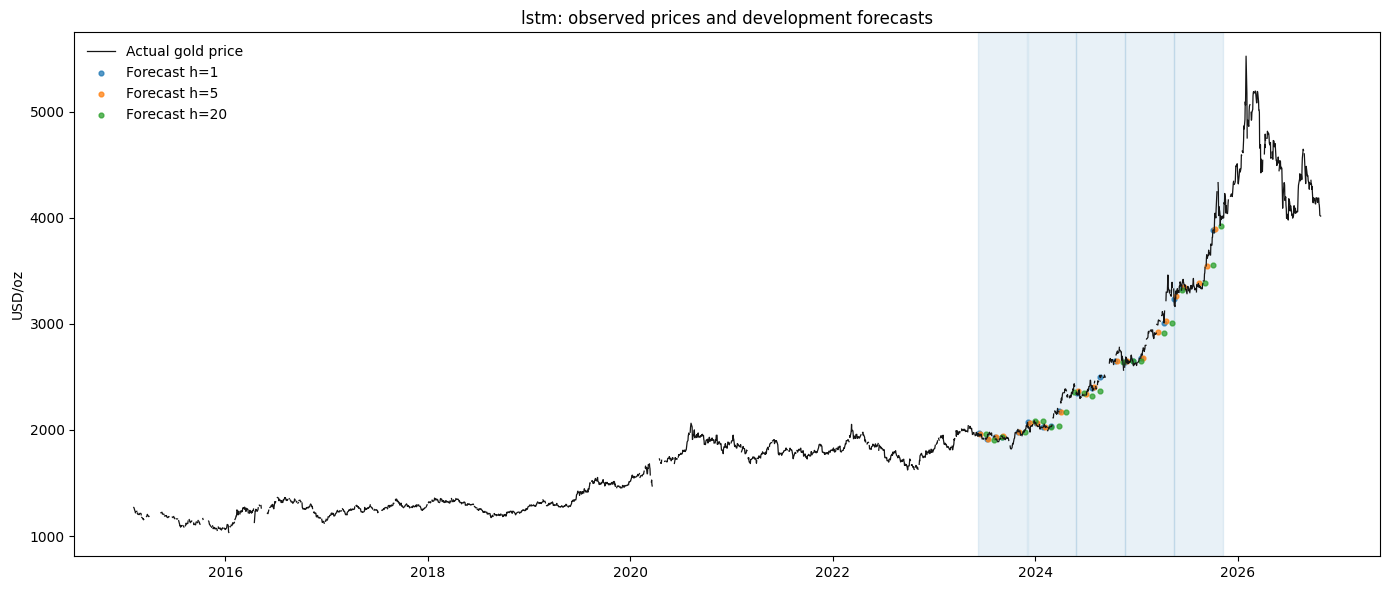

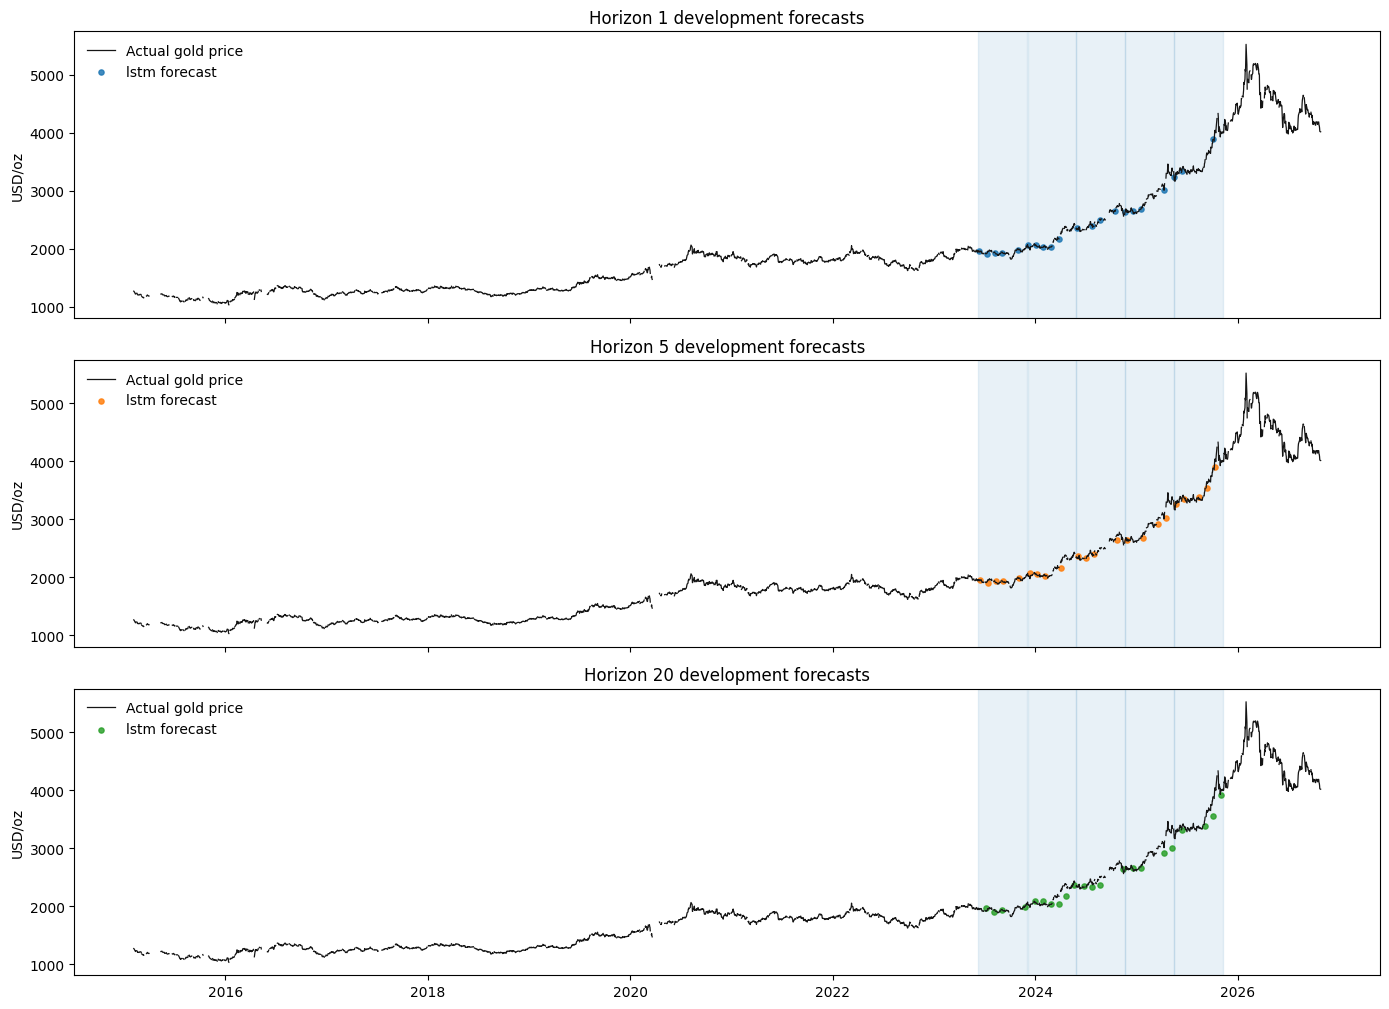

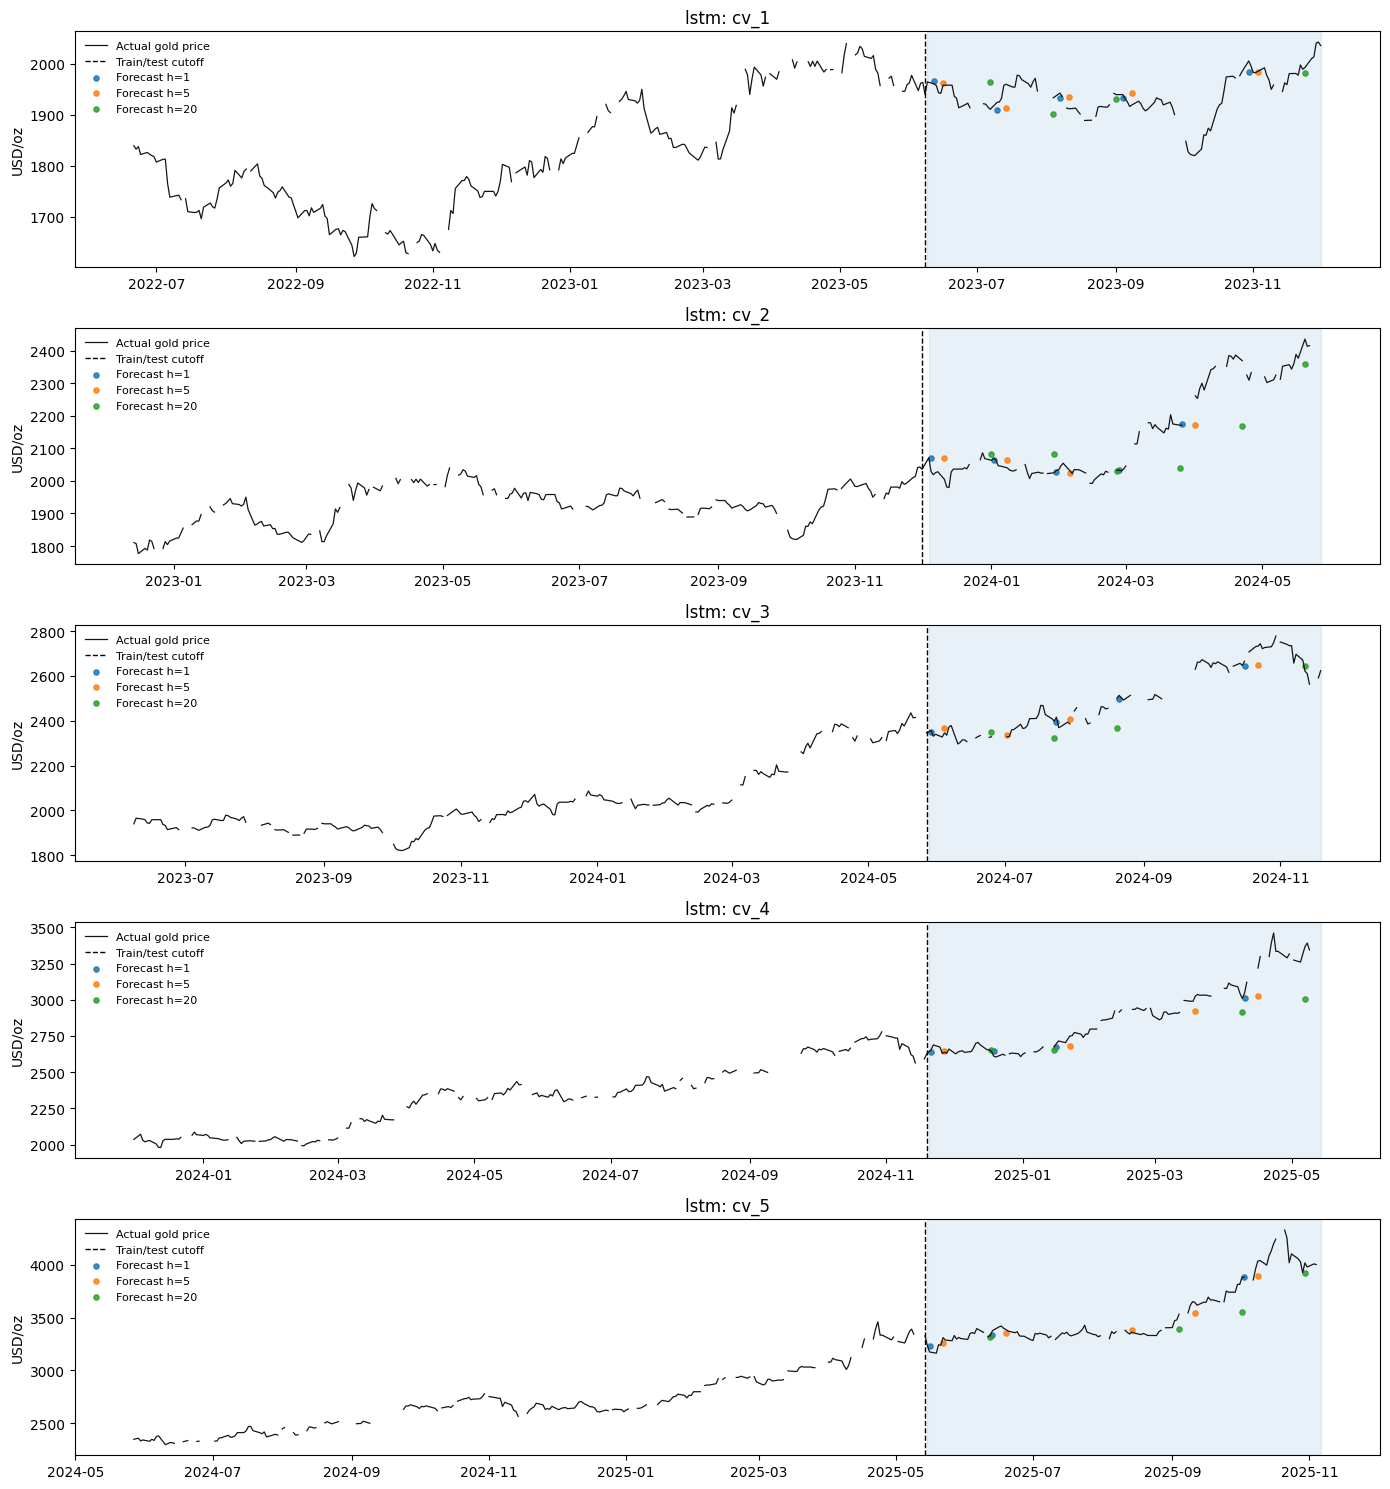

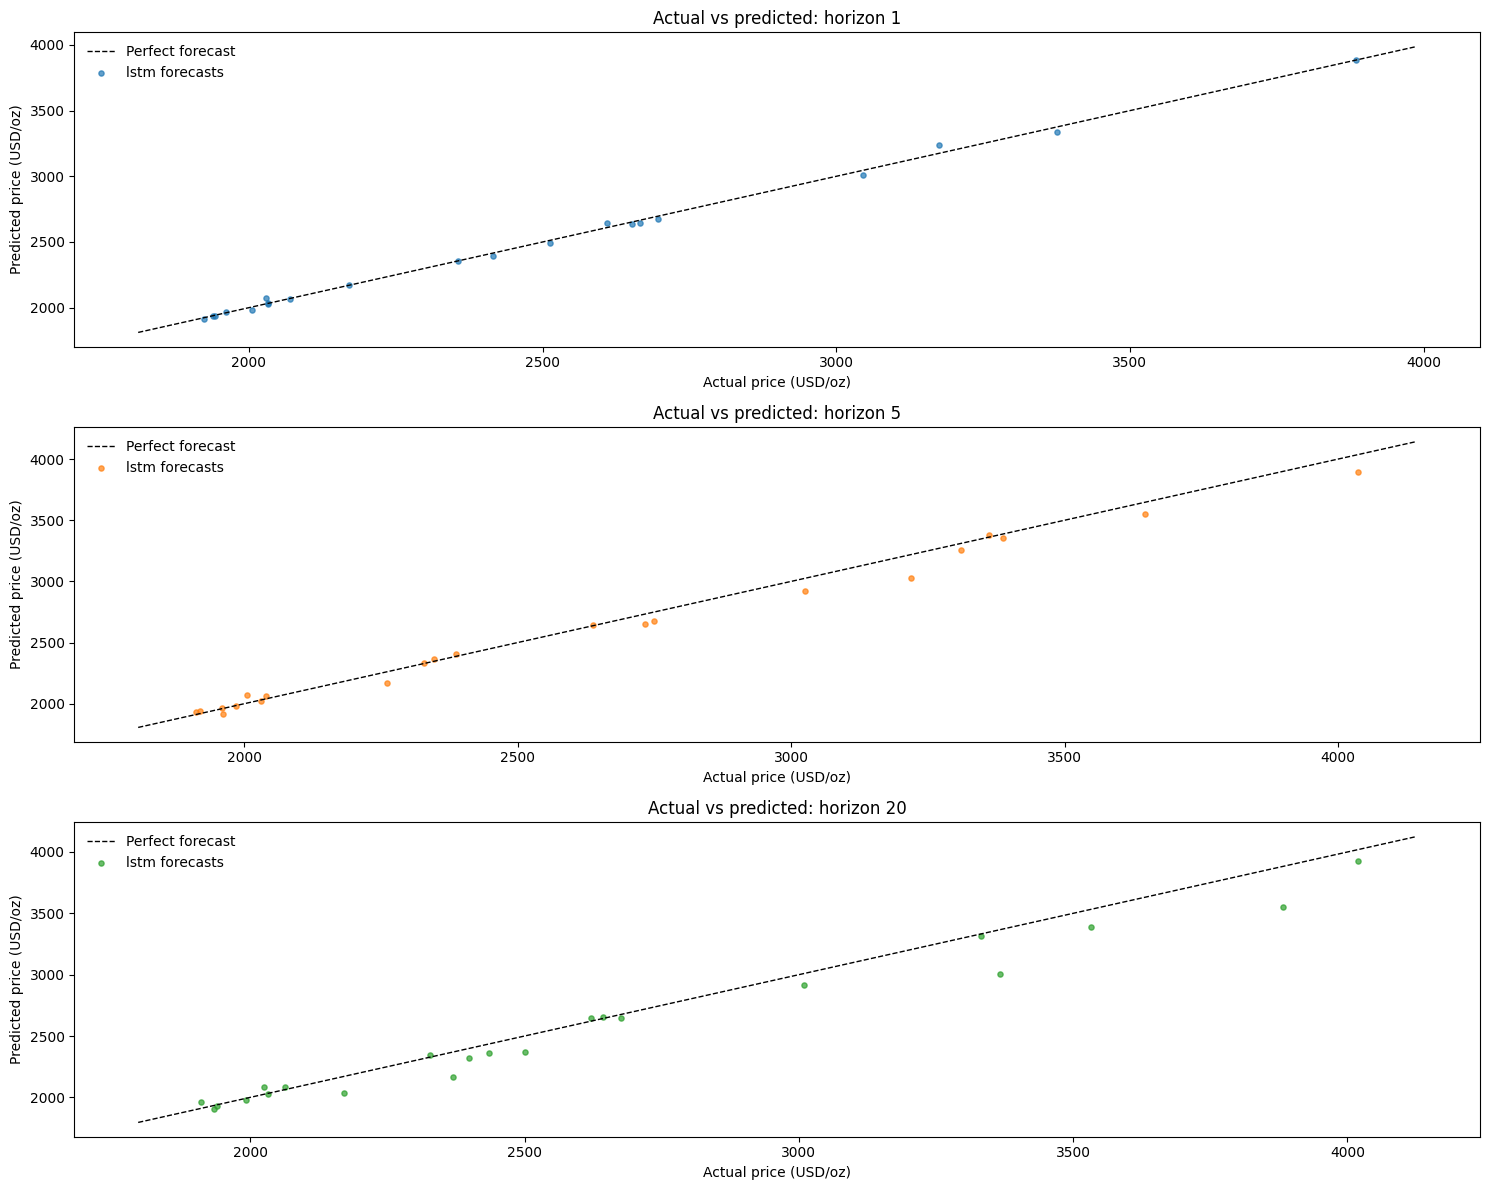

[PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/lstm/plots/actual_and_forecasts_timeline.png'),
 PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/lstm/plots/actual_and_forecasts_by_horizon.png'),
 PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/lstm/plots/actual_and_forecasts_by_fold.png'),
 PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/lstm/plots/actual_vs_predicted_scatter.png')]

In [7]:
from gold_plot_utils import plot_model_cv

plot_model_cv(panel, cv_predictions, folds, KIND, cfg, ROOT / 'artifacts' / KIND)

## 7. Lock the final configuration and evaluate the untouched holdout
The default is off so you can review development results first. Set
`final_holdout_enabled` to true in `config.json` when ready. This is an experiment guard,
not a request for additional permission. The function chooses parameters using development
history, records them before scoring, and preserves existing holdout results.

In [8]:
# Load the shared experiment configuration.
cfg = load_config()
# Holdout runs once, and parameters are locked before its results are scored.
if cfg['final_holdout_enabled']:
    holdout_predictions, holdout_metrics, locked_parameters = evaluate_holdout(
        KIND, panel, features, folds, cfg, trials=trials)
    display(holdout_metrics)
    display(locked_parameters)
else:
    print('Holdout not evaluated. Development predictions remain available for review.')

E0000 00:00:1793547153.997639  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793547159.714612  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

  candidate 1/3: inner MAE=97.147


E0000 00:00:1793547164.990711  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


  candidate 2/3: inner MAE=83.803


E0000 00:00:1793547172.610142  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793547181.706646  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

  candidate 3/3: inner MAE=81.098


E0000 00:00:1793547188.909418  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793547195.519192  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,lstm,holdout,1,11,60.251516,114.788449,1.268776,5.171657,58.936364,-0.022315
1,lstm,holdout,5,9,164.927782,251.375181,3.609102,14.156490,162.440000,-0.015315
2,lstm,holdout,20,12,331.459008,457.261541,7.053936,28.450611,338.485000,0.020757


{'group': 'external', 'lookback': 60, 'units': 32}

## 8. Refit the locked model and generate future forecasts
Run after the final holdout stage. The forecast starts from the latest observed gold quote.
Only the configured horizons are returned. Future actual external factors are not supplied.
Artifacts include the fitted model, input feature names, preprocessing where applicable,
locked configuration, predictions and metrics. No calibrated uncertainty intervals are claimed.

In [9]:
locked = ROOT / 'artifacts' / KIND / 'locked_parameters.json'
if cfg['final_holdout_enabled'] and locked.exists():
    # Refit reuses the locked configuration from artifacts/<kind>/locked_parameters.json.
    future_forecast = refit_and_forecast(KIND, panel, features, cfg)
    display(future_forecast)
else:
    print('Final refit waits for the parameter-lock stage.')

E0000 00:00:1793547201.957220  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1793547210.205453  673975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

,origin,horizon,target_date,forecast,model
0,2026-10-26,1,2026-10-27,4002.227551,lstm
1,2026-10-26,5,2026-11-02,3976.928600,lstm
2,2026-10-26,20,2026-11-23,3918.455264,lstm


## 9. Optional holdout and future forecast plots

These figures appear only when the matching artifacts exist:
- `artifacts/<model>/holdout_predictions.csv` after a locked holdout run;
- `artifacts/<model>/future_forecast.csv` after the final refit.

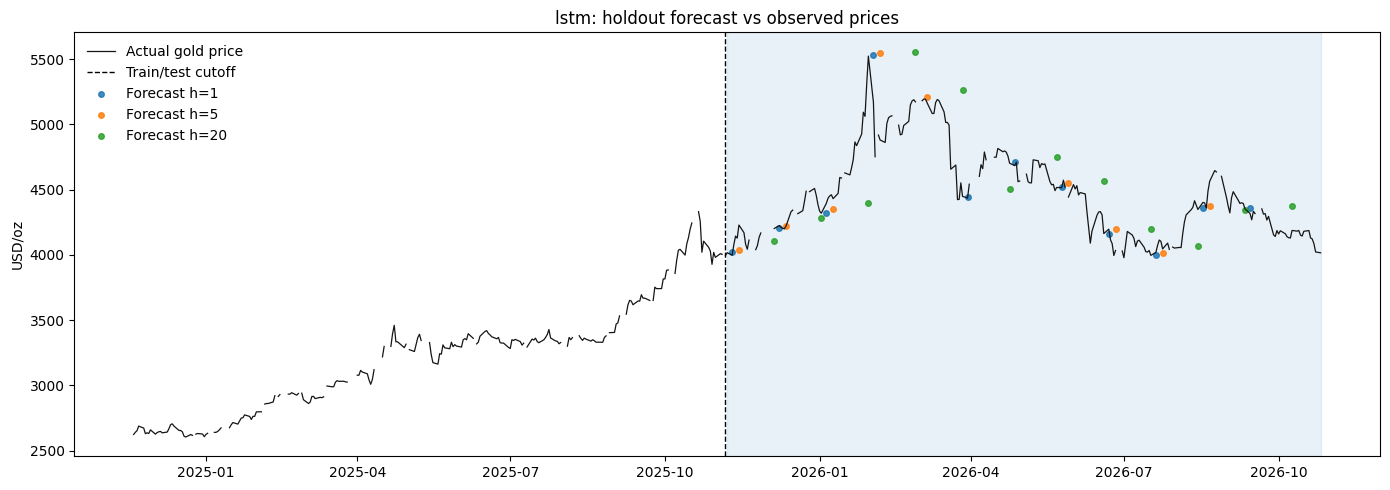

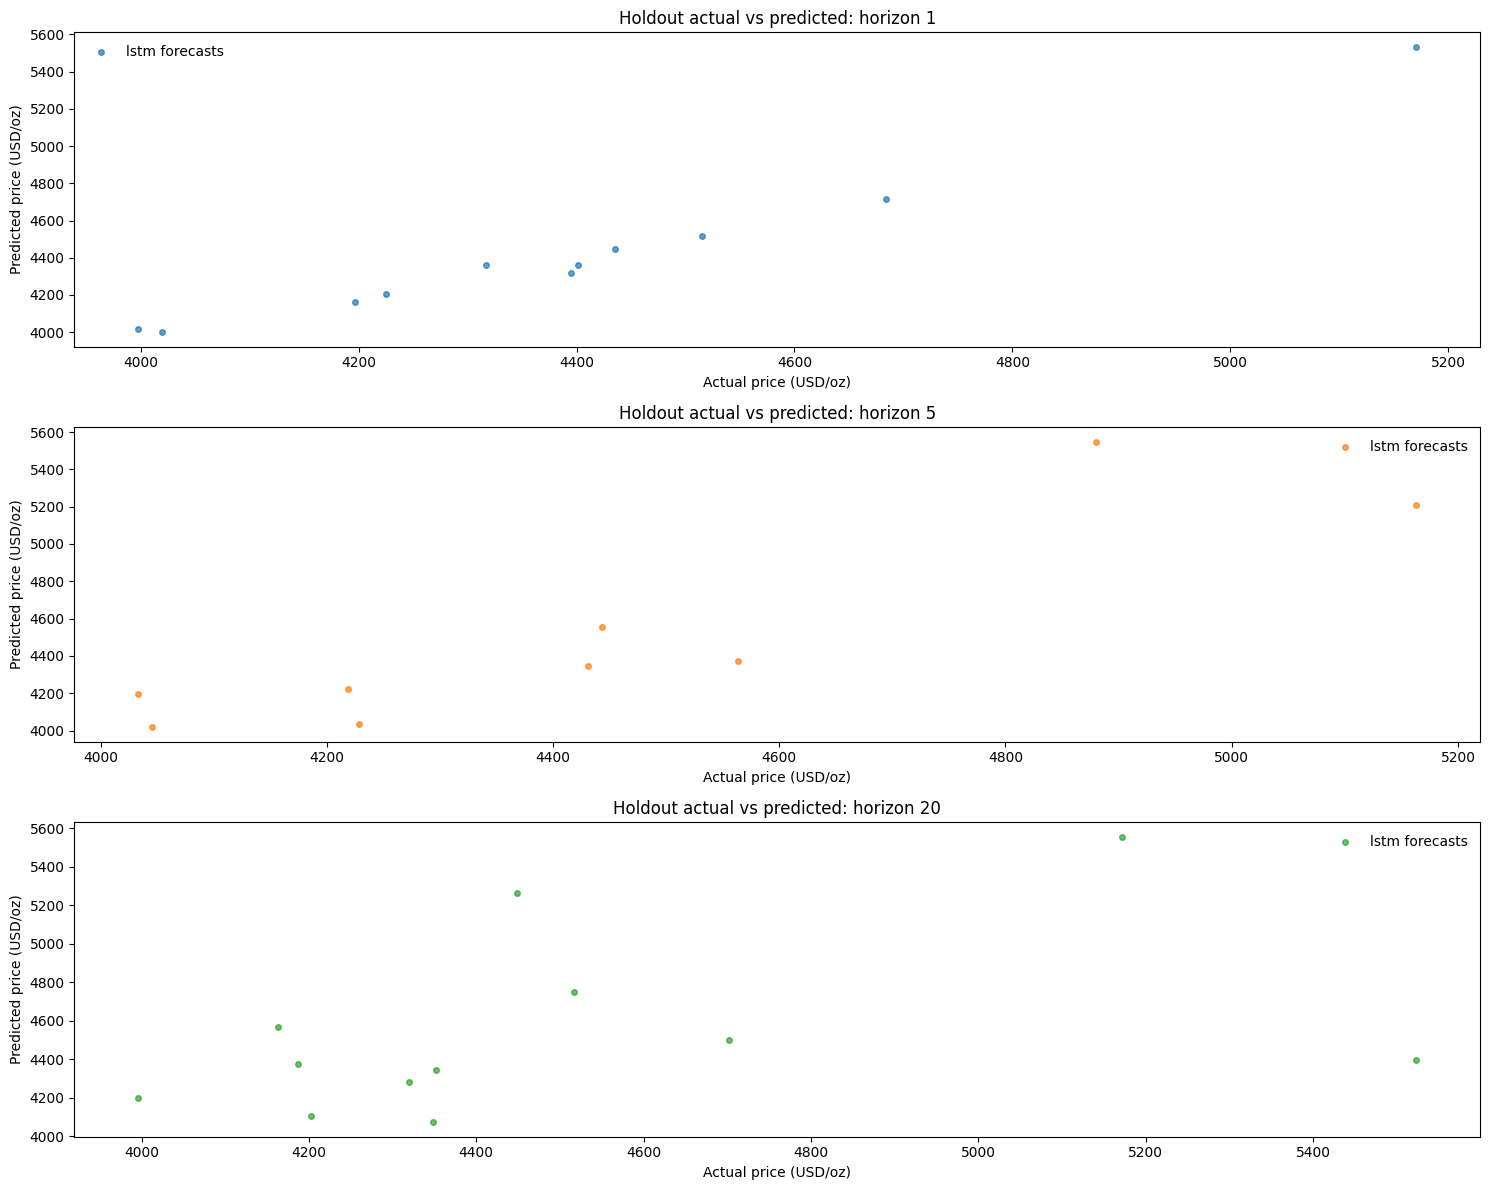

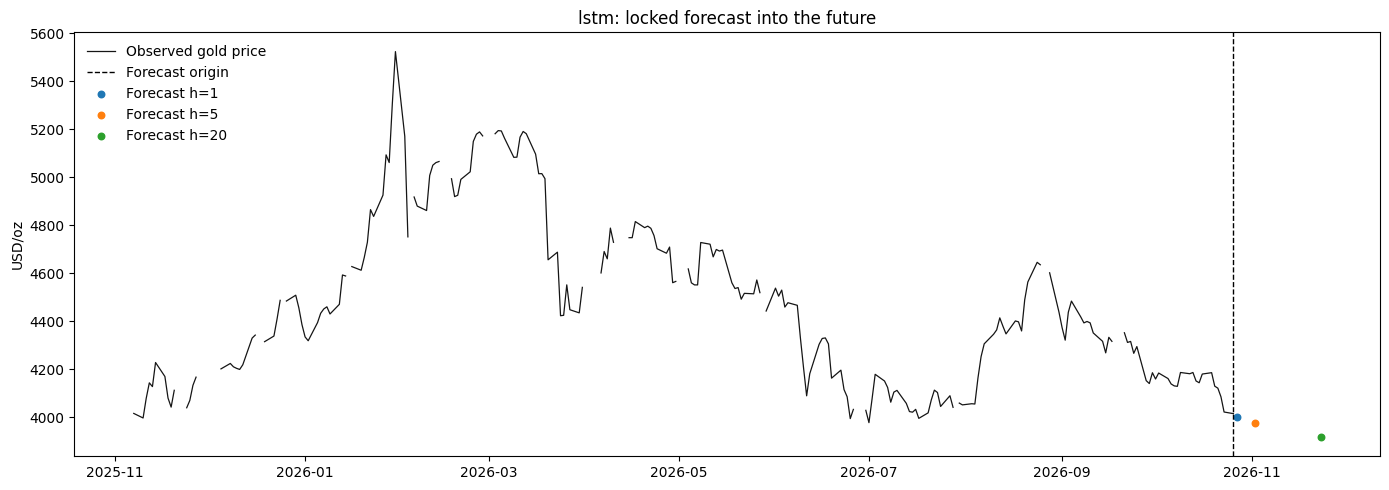

In [10]:
from gold_plot_utils import plot_model_holdout, plot_future_forecast

out_dir = ROOT / 'artifacts' / KIND
holdout_path = out_dir / 'holdout_predictions.csv'
future_path = out_dir / 'future_forecast.csv'
if holdout_path.exists():
    holdout_predictions = pd.read_csv(holdout_path, parse_dates=['origin', 'target_date'])
    plot_model_holdout(panel, holdout_predictions, folds, KIND, cfg, out_dir)
else:
    print('No holdout predictions yet.')
if future_path.exists():
    future_forecast = pd.read_csv(future_path, parse_dates=['origin', 'target_date'])
    plot_future_forecast(panel, future_forecast, KIND, cfg, out_dir)
else:
    print('No future forecast yet.')